# Неделя 3 — Лемматизация и морфоанализ spaCy

Цель: леммы, POS, Morph и сравнение с Porter/Snowball. Английская морфология не эквивалентна русской: падеж/число указываются только когда они реально присутствуют в разборе.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'nlp_project').exists() else Path.cwd().parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import json
import pandas as pd
import numpy as np
from IPython.display import display, Image, Markdown
from nlp_project.core import corpus, clean, tokens, metrics, SEED
df = corpus()
train, val, test = [df[df.split == s].copy() for s in ('train', 'validation', 'test')]


,word,lemma,pos,morph,porter,snowball
0,so,so,ADV,,so,so
1,there,there,PRON,,there,there
2,is,be,VERB,Mood=Ind|Number=Sing|Person=3|Tense=Pres|VerbF...,is,is
3,no,no,DET,,no,no
4,way,way,NOUN,Number=Sing,way,way
5,for,for,SCONJ,,for,for
6,me,i,PRON,Case=Acc|Number=Sing|Person=1|PronType=Prs,me,me
7,to,to,PART,,to,to
8,plug,plug,VERB,VerbForm=Inf,plug,plug
9,it,it,PRON,Case=Acc|Gender=Neut|Number=Sing|Person=3|Pron...,it,it


,частота слова
word,
the,517
i,375
it,311
and,311
is,242
a,217
this,204
to,195
phone,162


,частота леммы
lemma,
the,517
be,451
i,404
it,311
and,311
a,217
this,204
to,196
phone,170


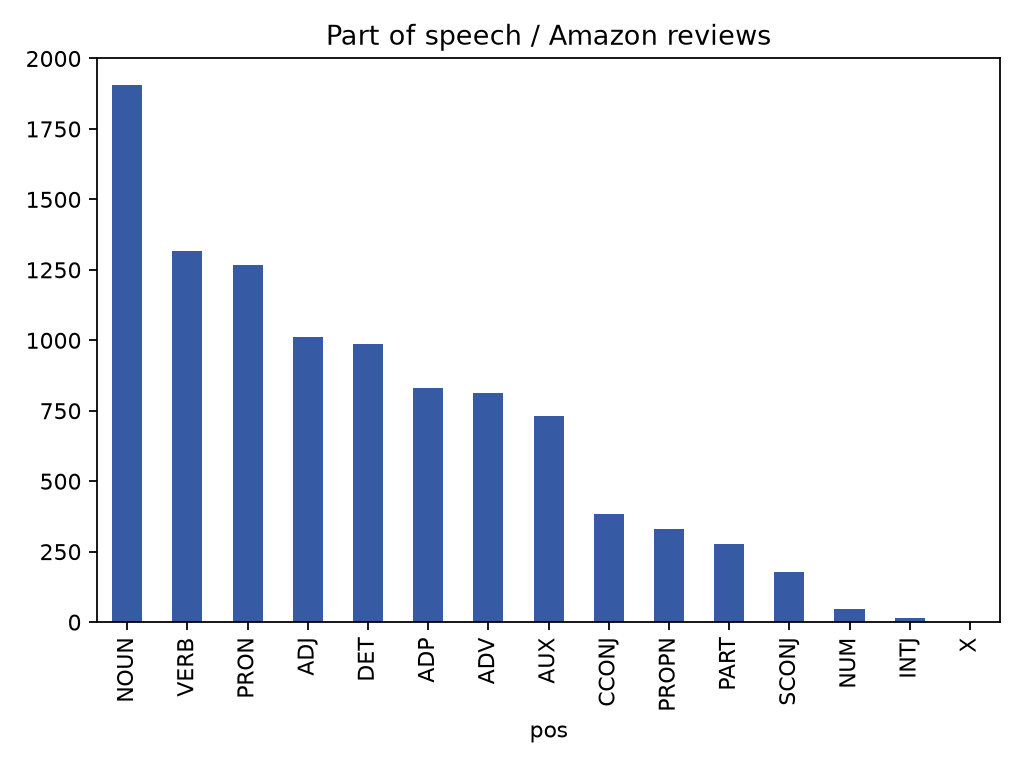

In [2]:
from nlp_project.core import morphology
comparison = morphology(train.head(20).text.tolist())
display(comparison[['word','lemma','pos','morph','porter','snowball']].drop_duplicates().head(40))
full = pd.read_csv(ROOT / 'reports/morphology.csv')
display(full.word.value_counts().head(50).to_frame('частота слова'))
display(full.lemma.value_counts().head(50).to_frame('частота леммы'))
display(Image(filename=str(ROOT / 'reports/figures/pos.png')))


## Выводы

Стемминг отсекает окончания без контекста, лемматизация учитывает словарную форму и POS. Полные топ-50 сохранены в отчётах. spaCy может ошибаться на разговорных фрагментах; это автоматическая, а не эталонная морфология.